# Activation và loss

Một ứng dụng của câu lạc bộ nhận ba việc: đoán số phút hoàn thành bài, đoán bài có cần đồ thị hay không, và chọn đúng một trong ba mức độ khó. Cùng là “mạng cho ra số”, nhưng ba đầu ra mang ba ý nghĩa khác nhau. Nếu nối sigmoid, softmax và loss theo thói quen, code có thể chạy mà đang giải sai bài. Ta sẽ chọn từ ý nghĩa nhãn, rồi kiểm bằng ví dụ có thể tính tay.

> **Mục tiêu sau bài này**
>
> - Chọn activation cho hidden layer, giải thích độ nhạy qua đạo hàm và chọn khởi tạo giữ thang đo qua nhiều lớp.
> - Phân biệt logit, xác suất, nhãn lớp và nhãn nhiều thuộc tính.
> - Ghép đầu ra với MSE, MAE, BCEWithLogitsLoss hoặc CrossEntropyLoss theo ý nghĩa nhãn.
> - Kiểm shape, dtype, reduction, loss ở bước đầu và tránh sigmoid/softmax hai lần.

## Activation là một phép biến đổi có mục đích

MLP cần phi tuyến giữa các lớp. ReLU giữ phần dương, đặt phần âm về 0. Tanh đưa số về khoảng $(-1,1)$; sigmoid đưa về $(0,1)$. Hãy nhìn đồ thị trước khi thuộc tên: ReLU có một cổng mở hoặc đóng, còn tanh và sigmoid dần nằm ngang ở hai đầu. Khi đầu ra gần như không đổi dù đầu vào đổi, gradient cũng nhỏ.



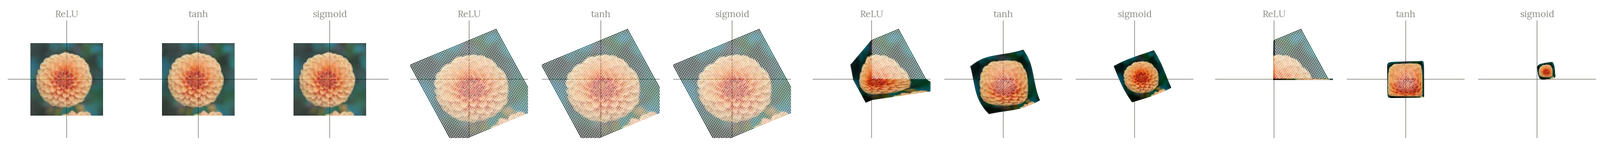

Các công thức là $\operatorname{ReLU}(z)=\max(0,z)$, $\sigma(z)=1/(1+e^{-z})$ và $\tanh z=(e^{z}-e^{-z})/(e^{z}+e^{-z})$. Đạo hàm của sigmoid và tanh đọc được ngay từ đầu ra: $\sigma'(z)=\sigma(z)(1-\sigma(z))$, lớn nhất $1/4$ tại 0; $\tanh'(z)=1-\tanh^2 z$, lớn nhất 1 tại 0. ReLU có đạo hàm 1 khi $z>0$ và 0 khi $z<0$. Tại đúng $z=0$ ReLU không khả vi; PyTorch quy ước đạo hàm bằng 0 ở đó. Pre-activation là tổng của nhiều số thực nên hầu như không bao giờ rơi đúng vào 0, và quy ước này không ảnh hưởng tới training.

In [ ]:
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.manual_seed(13)
z = torch.tensor([-10., 0., 10.], requires_grad=True)
torch.sigmoid(z).sum().backward()
print('sigmoid :', [round(v, 6) for v in torch.sigmoid(z).tolist()])
print("sigmoid':", [round(v, 6) for v in z.grad.tolist()])
z.grad = None                       # xóa gradient cũ trước lần backward thứ hai
torch.tanh(z).sum().backward()
print("tanh'   :", [round(v, 6) for v in z.grad.tolist()])
r = torch.tensor([-2., 0., 3.], requires_grad=True)
torch.relu(r).sum().backward()
print('relu    :', torch.relu(r).tolist(), "relu':", r.grad.tolist())

sigmoid : [4.5e-05, 0.5, 0.999955]
sigmoid': [4.5e-05, 0.25, 4.5e-05]
tanh'   : [0.0, 1.0, 0.0]
relu    : [0.0, 0.0, 3.0] relu': [0.0, 0.0, 1.0]


Hàng `sigmoid'` cho $0.25$ ở giữa và $4.5\cdot10^{-5}$ ở hai đầu; `tanh'` bằng 1 ở giữa và tròn về 0 trong float32 tại $|z|=10$. Một neuron ẩn bão hòa vì thế gần như ngừng học: mọi gradient đi qua nó bị nhân với một số gần 0. Đây là độ nhạy của riêng activation, chưa có loss. Ở lớp đầu ra, sigmoid ghép với BCE cho đạo hàm theo logit rút gọn thành $\sigma(z)-y$ (kiểm ở mục nhị phân), nên bão hòa ở lớp cuối không gây cùng vấn đề.

ReLU không bão hòa ở phía dương và tính rất rẻ, vì thế là lựa chọn mặc định cho hidden layer. Đổi lại, một neuron có pre-activation âm trên mọi mẫu, chẳng hạn sau một bước cập nhật quá lớn đẩy bias xuống rất âm, cho đầu ra 0 và gradient 0 cho chính trọng số của nó. Neuron ấy “chết” và không tự hồi lại. LeakyReLU, $\max(0.01z,z)$, giữ một độ dốc nhỏ phía âm để neuron vẫn nhận gradient.

**Hỏi nhanh.** Một neuron ẩn dùng sigmoid có $z \approx 8$ trên hầu hết các mẫu train. Trọng số đi vào neuron ấy được cập nhật thế nào?

- A. Rất mạnh, vì $z$ lớn thì gradient lớn
- B. Gần như đứng yên, vì $\sigma'(8)$ rất nhỏ
- C. Bình thường, vì BCE đã triệt tiêu thừa số $\sigma'$
- D. Đứng yên hoàn toàn, giống một neuron ReLU đã chết

<details><summary>Đáp án</summary>

B. Gần như đứng yên, vì $\sigma'(8)$ rất nhỏ

$\sigma(8) \approx 0.99966$, nên $\sigma'(8) = \sigma(8)(1 - \sigma(8)) \approx 3.4\cdot 10^{-4}$, và mọi gradient đi qua neuron đều bị nhân với số này. Phép rút gọn thành $\sigma(z) - y$ chỉ xảy ra khi sigmoid nằm ngay trước BCE ở lớp đầu ra, không áp dụng cho neuron ẩn. Gradient rất nhỏ nhưng vẫn khác 0, khác với ReLU chết có gradient đúng bằng 0.

</details>

**Hỏi nhanh.** ReLU không có đạo hàm tại $z = 0$. Vì sao huấn luyện bằng autograd vẫn chạy bình thường?

- A. Autograd quy ước một giá trị tại 0, và $z$ rất hiếm khi đúng bằng 0
- B. Đạo hàm tại 0 bằng $1/2$, trung bình của hai phía
- C. Optimizer tự bỏ qua các mẫu có $z = 0$ trong batch
- D. Float32 không biểu diễn được đúng số 0

<details><summary>Đáp án</summary>

A. Autograd quy ước một giá trị tại 0, và $z$ rất hiếm khi đúng bằng 0

Output ở trên cho thấy PyTorch lấy đạo hàm bằng 0 tại 0. Mọi giá trị trong $[0, 1]$ đều là một lựa chọn hợp lệ ở điểm gãy. Đạo hàm theo nghĩa thông thường không tồn tại tại 0, nên “bằng $1/2$” không phải sự thật, chỉ là một quy ước khác. Optimizer không xét từng mẫu, và float32 biểu diễn đúng được số 0.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 47](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=20)

</details>

## Qua nhiều lớp: thang đo và khởi tạo

Một hidden layer tính $z_j=\sum_{i=1}^{n}w_{ji}a_i$ với $n$ đầu vào (fan-in). Giả sử các trọng số độc lập, trung bình 0, phương sai $\sigma_w^2$, và độc lập với đầu vào. Khi đó các số hạng không tương quan với nhau và

$$\operatorname{Var}(z_j)=n\,\sigma_w^2\,\mathbb E[a_i^2].$$

Với ReLU và pre-activation đối xứng quanh 0, nửa âm bị đặt về 0 nên $\mathbb E[a^2]$ bằng một nửa phương sai pre-activation của lớp trước. Qua mỗi lớp, phương sai vì thế nhân với $n\sigma_w^2/2$. Hệ số này lặp lại ở mọi lớp nên tác dụng là lũy thừa: nhỏ hơn 1 thì tín hiệu co theo cấp số nhân, lớn hơn 1 thì nổ. Lan truyền ngược đi qua chính các ma trận ấy (chuyển vị) và các mặt nạ ReLU, nên gradient về các lớp đầu co hoặc nổ theo cùng cách. Đặt hệ số bằng 1 cho

$$\sigma_w=\sqrt{2/n},$$

gọi là khởi tạo He (Kaiming), lựa chọn chuẩn cho mạng ReLU. Phương sai chỉ quyết định thang đo; bản thân các trọng số vẫn phải rút ngẫu nhiên, vì các neuron khởi tạo giống hệt nhau nhận cùng gradient và giống nhau mãi (bài 3.2). Tanh gần như là $z$ quanh 0 nên cần $\sigma_w=\sqrt{1/n}$; khởi tạo Xavier (Glorot) lấy trung bình fan-in và fan-out theo cùng tinh thần. Sigmoid còn thêm một hệ số: mỗi lớp nhân gradient với $\sigma'\le1/4$, nên chồng nhiều lớp sigmoid làm gradient của các lớp đầu tắt dần ngay cả khi trọng số vừa phải.

Thí nghiệm dưới đây dùng 10 lớp ReLU rộng 256, không bias, 512 mẫu đầu vào chuẩn. Hai cấu hình dùng cùng các ma trận ngẫu nhiên, chỉ khác hệ số nhân: $\mathcal N(0,0.01^2)$ hoặc He. Loss là trung bình đầu ra cuối, đủ để đo gradient chảy về lớp 1.

In [ ]:
def depth_probe(std, depth=10, width=256):
    torch.manual_seed(0)                   # cùng dữ liệu và cùng ma trận cho mọi std
    h = torch.randn(512, width)
    weights = [(torch.randn(width, width) * std).requires_grad_() for _ in range(depth)]
    scales = []
    for w in weights:
        pre = h @ w                        # pre-activation, shape (512, 256)
        scales.append(pre.std().item())
        h = torch.relu(pre)
    h.mean().backward()                    # loss đơn giản để đo gradient về lớp 1
    return scales, weights[0].grad.norm().item()

scales_small, grad_small = depth_probe(0.01)
scales_he, grad_he = depth_probe((2 / 256) ** 0.5)
print('std pre-activation ở lớp 1, 4, 7, 10 và ‖grad W1‖:')
for name, scales, grad in [('N(0,0.01²)', scales_small, grad_small), ('He', scales_he, grad_he)]:
    print(f'{name:10s}', [float(f'{v:.2g}') for v in scales[::3]], f'{grad:.2g}')

std pre-activation ở lớp 1, 4, 7, 10 và ‖grad W1‖:
N(0,0.01²) [0.16, 0.00021, 3.1e-07, 4.9e-10] 2.8e-10
He         [1.4, 1.3, 1.3, 1.4] 0.091


Lý thuyết dự đoán được các con số này. Với $\sigma_w=0.01$ và $n=256$, phương sai nhân $256\cdot10^{-4}/2=0.0128$ mỗi lớp, tức độ lệch chuẩn nhân khoảng $0.113$. Lớp 1 nhận đầu vào chuẩn nên có std $\sqrt{256}\cdot0.01=0.16$; sau chín lớp nữa còn $0.16\cdot0.113^{9}\approx5\cdot10^{-10}$, đúng như output. Gradient về lớp 1 nhỏ hơn bản He khoảng $3\cdot10^{8}$ lần, nên mọi bước cập nhật gần như bằng 0 và loss đứng yên. Đầu ra không bằng 0, cũng còn rất xa giới hạn của float32 (cỡ $10^{-38}$): tín hiệu chỉ bị co tới mức vô dụng. Với He, std giữ quanh 1.4 ở mọi lớp.

Hai cấu hình khác nhau đúng hệ số $0.01/\sqrt{2/256}\approx0.113$ ở mỗi lớp. Vì ReLU thuần nhất dương, $\operatorname{ReLU}(cz)=c\operatorname{ReLU}(z)$ với mọi $c>0$, nên trong mạng không bias, nhân trọng số của một lớp với $c$ thì mọi lớp phía sau nhân đúng $c$. Trên trục log, đường của $\mathcal N(0,0.01^2)$ vì thế gần như một đường thẳng đi xuống, cùng độ dốc ở mọi lớp.



`nn.Linear` của PyTorch mặc định lấy trọng số đều trong $[-1/\sqrt n,1/\sqrt n]$, tức độ lệch chuẩn $1/\sqrt{3n}$, nhỏ hơn He. Với mạng ReLU sâu tự viết, gọi `nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')` để giữ thang đo. BatchNorm (bài 3.6) và kết nối residual (bài 5.2) là hai cách khác giữ thang đo khi mạng rất sâu.

**Hỏi nhanh.** Mạng ReLU 10 lớp, không có bias. Giữ nguyên đầu vào, nhân mọi trọng số của cả 10 lớp với 2. Đầu ra cuối thay đổi thế nào?

- A. Nhân 2, vì mỗi trọng số chỉ nhân 2
- B. Nhân 20, vì hệ số cộng dồn qua 10 lớp
- C. Nhân $2^{10} = 1024$
- D. Không đoán được, vì ReLU là hàm phi tuyến

<details><summary>Đáp án</summary>

C. Nhân $2^{10} = 1024$

$\operatorname{ReLU}(2z) = 2\operatorname{ReLU}(z)$, nên mỗi lớp nhân đầu ra thêm 2, và các hệ số nhân dồn lại thành $2^{10}$. ReLU là hàm phi tuyến, nhưng tính chất này đủ để đoán chính xác. Cũng vì vậy mà khởi tạo với độ lệch chuẩn chỉ gấp đôi He đã làm tín hiệu tăng gấp đôi sau mỗi lớp. Có bias thì tính chất này không còn đúng chính xác.

</details>

**Hỏi nhanh.** Gradient đi ngược qua 10 lớp sigmoid. Bỏ qua trọng số, coi chúng bằng 1, thì tích các đạo hàm sigmoid trên đường đi lớn nhất là bao nhiêu?

- A. $2.5$, tức mười lần $1/4$ cộng lại
- B. $0.25$, vì chỉ lớp cuối được tính
- C. $0$, vì sigmoid lúc nào cũng bão hòa
- D. $(1/4)^{10} \approx 10^{-6}$

<details><summary>Đáp án</summary>

D. $(1/4)^{10} \approx 10^{-6}$

Chain rule nhân các đạo hàm với nhau, không cộng. Mỗi thừa số $\sigma' \le 1/4$, và chỉ đạt $1/4$ khi $z = 0$, nên tích không vượt quá $(1/4)^{10} \approx 9.5\cdot 10^{-7}$. Sigmoid không phải lúc nào cũng bão hòa, và ngay cả khi không bão hòa, tích đã rất nhỏ. Trọng số lớn có thể bù hệ số này, nhưng lại đẩy $z$ ra xa 0 và gây bão hòa.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 55](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=23)

</details>

## Hồi quy: đo mức sai bằng đơn vị

Đoán thời gian là hồi quy; đầu ra cuối thường để linear. Nếu bắt đầu bằng sigmoid, ta ép số phút vào $(0,1)$ mà không có lý do. Khi target đã đổi thang về khoảng ấy, vẫn phải cân nhắc việc ép miền và đổi ngược đơn vị.

Với phần dư $r=\hat y-y$, MSE trung bình $r^2$, MAE trung bình $|r|$. MSE có đơn vị phút bình phương, MAE có đơn vị phút. MSE phạt một sai số 10 nặng gấp 25 lần sai số 2, còn MAE nặng gấp 5 lần. Đó là lựa chọn về hậu quả của lỗi lớn, không đơn thuần là chọn hàm “dễ chạy”. Nếu model chỉ được đoán một hằng số, MSE chọn trung bình của target, còn MAE chọn trung vị; vài bài có thời gian bất thường vì thế kéo model MSE đi xa hơn nhiều. MAE không khả vi tại $r=0$; như với ReLU, autograd quy ước một giá trị ở điểm gãy.



In [ ]:
prediction = torch.tensor([1., 5., 12.])
target = torch.tensor([2., 3., 2.])
assert prediction.shape == target.shape
print('residual:', (prediction - target).tolist())
print('MSE:', round(F.mse_loss(prediction, target).item(), 4))
print('MAE:', round(F.l1_loss(prediction, target).item(), 4))
print('per item:', F.mse_loss(prediction, target, reduction='none').tolist())

residual: [-1.0, 2.0, 10.0]
MSE: 35.0
MAE: 4.3333
per item: [1.0, 4.0, 100.0]


Phần dư $(-1,2,10)$ cho MSE $(1+4+100)/3=35$ và MAE $(1+2+10)/3=13/3$. Một mẫu cuối đóng phần lớn loss MSE. Kiểm `reduction='none'` giúp phát hiện một dòng dữ liệu bất thường thay vì chỉ nhìn con số trung bình. Huber loss nối hai cách: gần 0 giống bình phương, xa giống trị tuyệt đối. Khi đề chấm MAE, train bằng L1 hoặc Huber thường khớp metric hơn MSE; chọn cụ thể bằng validation.



**Hỏi nhanh.** Đổi đơn vị nên target và dự đoán đều nhân 10. MSE thay đổi thế nào?

- A. Nhân 10, giống phần dư
- B. Nhân 20, vì cả hai đại lượng cùng đổi
- C. Giữ nguyên, vì MSE là một trung bình
- D. Nhân 100

<details><summary>Đáp án</summary>

D. Nhân 100

Phần dư nhân 10, bình phương của nó nhân 100. MAE thì chỉ nhân 10. Lấy trung bình không xóa được đơn vị, nên không so loss giữa hai thang đo chưa đổi về cùng đơn vị.

</details>

**Hỏi nhanh.** Năm bài có thời gian hoàn thành là 10, 12, 13, 15 và 90 phút. Nếu mô hình chỉ được đoán một hằng số, thì hằng số tốt nhất theo MSE và theo MAE lần lượt là bao nhiêu?

- A. Theo MSE là 28, theo MAE là 13
- B. Theo MSE là 13, theo MAE là 28
- C. Cả hai đều là 28
- D. Cả hai đều là 13

<details><summary>Đáp án</summary>

A. Theo MSE là 28, theo MAE là 13

Tổng $\sum(c - y_i)^2$ nhỏ nhất tại trung bình $140/5 = 28$. Tổng $\sum|c - y_i|$ nhỏ nhất tại trung vị 13. Một bài 90 phút kéo trung bình lên gấp đôi mức của bốn bài còn lại, còn trung vị gần như không đổi. Đề chấm MAE mà train bằng MSE thì mô hình bị kéo về phía những mẫu như vậy.

</details>



## Nhị phân: đầu ra một logit

Đoán “cần đồ thị” dùng nhãn $y\in\{0,1\}$. Mạng cho một số thực $z$, gọi là logit. Sigmoid biến $z$ thành xác suất $p$. Logit 0 tương ứng xác suất 0.5; logit dương nghiêng về lớp 1, âm nghiêng về lớp 0. Logit không bắt buộc nằm trong khoảng 0–1.

Binary cross-entropy là $-[y\log p+(1-y)\log(1-p)]$. Nếu tự tính sigmoid rồi log với $z$ rất lớn, làm tròn có thể cho $p=1$ và $\log(1-p)$ gặp lỗi số. Dùng BCEWithLogitsLoss để ghép hai phép bằng dạng ổn định:

$$\ell(z,y)=\max(z,0)-zy+\log(1+e^{-|z|}).$$

`log1p` tính $\log(1+t)$ ổn hơn khi $t$ rất nhỏ. Ta tự cài dạng này bằng NumPy rồi so thư viện:

In [ ]:
logits_np = np.array([-2., 0., 2., -1000., 1000.])
labels_np = np.array([0., 1., 1., 0., 1.])
stable_bce = np.maximum(logits_np, 0) - logits_np * labels_np
stable_bce += np.log1p(np.exp(-np.abs(logits_np)))
logits = torch.tensor(logits_np, requires_grad=True)
labels = torch.tensor(labels_np)
individual = F.binary_cross_entropy_with_logits(logits, labels, reduction='none')
print(np.round(stable_bce, 6).tolist())
print('match:', np.allclose(stable_bce, individual.detach().numpy()))
individual.sum().backward()
print('gradient:', [round(v, 6) for v in logits.grad.tolist()])

[0.126928, 0.693147, 0.126928, 0.0, 0.0]
match: True
gradient: [0.119203, -0.5, -0.119203, 0.0, 0.0]


Loss tại hai logit cực lớn nhưng đoán đúng vẫn hữu hạn. Gradient của tổng loss theo từng logit là $p-y$, nên tại $z=0,y=1$ nó là $-0.5$. Khi logit rất dương mà target là 0, gradient gần 1: mô hình sai rất tự tin vẫn nhận tín hiệu chỉnh rõ. Vì vậy model train với BCEWithLogitsLoss không có sigmoid ở lớp cuối; sigmoid chỉ gọi lúc suy luận, khi cần xác suất. Ngưỡng 0.5 cho xác suất tương đương ngưỡng 0 cho logit.



**Hỏi nhanh.** Mô hình có `nn.Sigmoid()` ở lớp cuối, và đầu ra ấy lại được đưa vào BCEWithLogitsLoss. Với mẫu có nhãn 0, loss không bao giờ xuống dưới mức nào?

- A. $0$, khi mô hình rất tự tin đoán đúng
- B. $0.313$, tức $\log(1 + e^{-1})$
- C. Không xác định, vì code báo lỗi kiểu dữ liệu
- D. $\log 2 \approx 0.693$

<details><summary>Đáp án</summary>

D. $\log 2 \approx 0.693$

Hàm loss coi $u = \sigma(z) \in (0, 1)$ là logit. Với nhãn 0, loss là $\log(1 + e^{u})$, luôn lớn hơn $\log 2$, giá trị đạt được khi $u \to 0$. Vì vậy loss không bao giờ xuống 0. Con số $0.313$ là mức sàn của nhãn 1, khi $u \to 1$. Code chạy im lặng, không báo lỗi gì; chỉ có loss đứng ở mức cao và xác suất đọc ra bị nén lại.

</details>

## Nhiều lớp: mỗi hàng là một bộ logits

Chọn đúng một độ khó trong ba lớp là multi-class. Mạng trả `(B, C)` logits. Softmax theo chiều lớp tạo $p_c=e^{z_c}/\sum_j e^{z_j}$, tổng bằng 1. CrossEntropyLoss nhận logits và target chỉ số lớp `(B,)` kiểu long; mặc định gộp log-softmax bên trong. Loss này cũng nhận target là phân phối xác suất `(B,C)` kiểu float, dùng cho nhãn mềm; bài này dùng chỉ số lớp.

Với logits $(\log2,0)$, softmax là $(2/3,1/3)$. Nếu nhãn đúng là 0, loss $-\log(2/3)=\log(3/2)$. Hai cách tính sau phải khớp:

In [ ]:
scores = torch.tensor([[np.log(2.), 0.], [0., np.log(2.)]], dtype=torch.float64)
classes = torch.tensor([0, 1], dtype=torch.long)
probabilities = scores.softmax(dim=1)
hand_loss = -probabilities[torch.arange(2), classes].log().mean()
correct_loss = F.cross_entropy(scores, classes)
double_softmax_loss = F.cross_entropy(probabilities, classes)
print(probabilities.tolist())
print(round(hand_loss.item(), 6), round(correct_loss.item(), 6))
print('softmax twice:', round(double_softmax_loss.item(), 6))
print('prediction:', scores.argmax(dim=1).tolist())

[[0.6666666666666666, 0.3333333333333333], [0.3333333333333333, 0.6666666666666666]]
0.405465 0.405465
softmax twice: 0.540306
prediction: [0, 1]


Hai loss đầu bằng nhau; dòng “softmax twice” khác vì thư viện coi hai xác suất 2/3 và 1/3 như logits mới. Code vẫn chạy, nhưng biến đổi đã nén chênh lệch trước khi loss thực hiện log-softmax. Để lấy lớp có xác suất lớn nhất, `scores.argmax(dim=1)` đủ: softmax giữ thứ tự, không cần tốn thêm phép tính.



**Hỏi nhanh.** Đầu ra `(B, 3)` là logits cho ba lớp loại trừ nhau. Ghép với hàm loss thế nào cho đúng?

- A. Qua softmax theo chiều lớp, rồi vào CrossEntropyLoss
- B. Qua sigmoid từng logit, rồi vào CrossEntropyLoss
- C. Đưa thẳng logits vào CrossEntropyLoss
- D. Qua softmax, rồi vào BCEWithLogitsLoss với nhãn one-hot

<details><summary>Đáp án</summary>

C. Đưa thẳng logits vào CrossEntropyLoss

CrossEntropyLoss đã gộp sẵn log-softmax bên trong. Đặt softmax hay sigmoid phía trước thì vẫn chạy, nhưng là giải một mục tiêu khác: dòng “softmax twice” cho 0.540 thay vì 0.405. Softmax rồi BCE vừa biến đổi hai lần, vừa bỏ mất ràng buộc chỉ có một lớp đúng.

</details>

Một mốc kiểm nhanh: khi mọi logit bằng nhau, mỗi lớp có xác suất $1/C$ và CE bằng $\log C$. Model mới khởi tạo cho logits nhỏ nên loss ở batch đầu nằm gần mốc này: $\log3\approx1.10$ với ba mức khó, $\log10\approx2.30$ với mười lớp. Loss đầu tiên xa hẳn mốc thường báo logits khởi đầu quá lớn hoặc nhãn bị ghép sai.

**Hỏi nhanh.** Bài phân loại 10 lớp, mô hình vừa khởi tạo. CrossEntropyLoss mặc định, lấy trung bình, ở batch đầu tiên bằng 17.5. Nhận định nào hợp lý nhất?

- A. Bình thường, có 10 lớp thì loss đầu luôn trên 10
- B. Logits khởi đầu quá lớn, vì mức bình thường là gần $\log 10$
- C. Learning rate quá nhỏ nên loss chưa kịp giảm
- D. Nhãn kiểu `long` phải đổi thành one-hot kiểu float trước

<details><summary>Đáp án</summary>

B. Logits khởi đầu quá lớn, vì mức bình thường là gần $\log 10$

Logits gần bằng nhau thì CE gần $\log 10 \approx 2.30$. Loss bằng 17.5 nghĩa là mô hình rất tự tin vào lớp sai, dấu hiệu logits lớn: khởi tạo quá to, đầu vào chưa chuẩn hóa, hoặc thiếu một phép chia thang đo. Batch đầu chưa qua bước cập nhật nào nên learning rate chưa có ảnh hưởng. CrossEntropyLoss nhận thẳng nhãn kiểu `long`.

</details>

## Nhiều thuộc tính và bảng hợp đồng

Một bài có thể thuộc cả “đồ thị” lẫn “DP”: hai thuộc tính không loại trừ nhau. Khi đó mỗi thuộc tính là một nhãn nhị phân riêng, model cho `(B,K)` logits và BCEWithLogitsLoss với target float cùng shape. Softmax sẽ ép các thuộc tính tranh nhau tổng xác suất 1, trái với ý nghĩa “cả hai đều đúng”. Khi suy luận, mỗi thuộc tính bật độc lập khi sigmoid của nó vượt ngưỡng; với ngưỡng 0.5, điều đó tương đương logit dương. Lấy argmax chỉ trả về một thuộc tính và làm mất đúng trường hợp “cả hai”.

| Bài toán | Đầu ra model | Target thông thường | Loss |
|---|---|---|---|
| Hồi quy một số | `(B,)` float | `(B,)` float | MSE hoặc MAE |
| Nhị phân | `(B,)` logits | `(B,)` float 0/1 | BCEWithLogitsLoss |
| Một trong C lớp | `(B,C)` logits | `(B,)` long | CrossEntropyLoss |
| K thuộc tính độc lập | `(B,K)` logits | `(B,K)` float 0/1 | BCEWithLogitsLoss |

Tính tay với hai thuộc tính đều đúng và logits bằng 0: mỗi sigmoid là 1/2, mỗi BCE là $\log2$. Reduction mean trên hai phần tử vẫn là $\log2$, còn sum là $2\log2$. Mean chia cho số phần tử tham gia: với target `(B,K)`, đó là $BK$, không phải $B$. Hai reduction chỉ khác nhau một hằng số nhân, nên có cùng điểm tối ưu; nhân loss với một hằng số dương không đổi nghiệm mà chỉ đổi độ lớn gradient. Với SGD, đổi reduction vì thế tương đương nhân learning rate với hằng số ấy.

**Hỏi nhanh.** Mô hình đa nhãn cho ba thuộc tính với logits $(1.2,\,-0.4,\,0.1)$, ngưỡng xác suất là 0.5. Những thuộc tính nào được dự đoán?

- A. Chỉ $\{0\}$, vì thuộc tính 0 có logit lớn nhất
- B. Chỉ $\{0\}$, vì chỉ softmax của nó vượt 0.5
- C. $\{0, 2\}$
- D. $\{0, 1, 2\}$, vì sigmoid luôn cho số dương

<details><summary>Đáp án</summary>

C. $\{0, 2\}$

Sigmoid từng logit cho $0.77$, $0.40$ và $0.525$, nên hai thuộc tính có logit dương vượt ngưỡng. Argmax và softmax, cho $0.65$, $0.13$, $0.22$, đều coi các thuộc tính loại trừ nhau, nên bỏ mất thuộc tính 2. Sigmoid luôn dương, nhưng ngưỡng là 0.5 chứ không phải 0.

</details>



## Bẫy cài đặt

Trước training, lấy một batch và viết ra tên chiều, miền nhãn, dtype và shape. CrossEntropyLoss cần chỉ số lớp kiểu long từ $0$ tới $C-1$: nhãn $1$ tới $C$ phải ánh xạ trước, rồi lưu mapping để dịch ngược khi suy luận. BCEWithLogitsLoss ngược lại cần target float cùng shape với logits. Lỗi shape hay gặp nhất là đầu ra `nn.Linear(h, 1)` có shape `(B,1)` còn nhãn có shape `(B,)`; các bài trước đã cho thấy phép trừ hai shape này broadcast thành `(B,B)`. Các loss phản ứng với cặp shape ấy, và với dtype sai, không giống nhau. Đoạn code đưa cùng một cặp tensor vào từng loss để so:

In [ ]:
import warnings

out = torch.tensor([[2.], [-1.], [0.5], [-3.]])     # (4, 1): đầu ra nn.Linear(h, 1)
y = torch.tensor([1., 0., 1., 0.])                  # (4,), float

def try_loss(name, call):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')         # đếm cảnh báo thay vì in ra
        try:
            value = call()
        except (ValueError, RuntimeError) as err:
            print(f'{name}: dừng, {type(err).__name__}')
            return
    print(f'{name}: chạy, loss {value.item():.4f}, {len(caught)} cảnh báo')

try_loss('BCE (4,1) và (4,)', lambda: F.binary_cross_entropy_with_logits(out, y))
try_loss('CE nhãn float    ', lambda: F.cross_entropy(torch.zeros(4, 3), y))
try_loss('L1  (4,1) và (4,)', lambda: F.l1_loss(out, y))
try_loss('BCE sau squeeze  ', lambda: F.binary_cross_entropy_with_logits(out.squeeze(1), y))

BCE (4,1) và (4,): dừng, ValueError
CE nhãn float    : dừng, RuntimeError
L1  (4,1) và (4,): chạy, loss 1.7500, 1 cảnh báo
BCE sau squeeze  : chạy, loss 0.2407, 0 cảnh báo


BCEWithLogitsLoss dừng với thông báo `Target size (torch.Size([4])) must be the same as input size (torch.Size([4, 1]))`; CrossEntropyLoss nhận nhãn float `(B,)` thì báo `expected scalar type Long but found Float`. Lỗi báo ra là lỗi dễ. L1, cũng như MSE, chỉ phát một cảnh báo rồi lấy trung bình trên 16 cặp $(i,j)$, phần lớn là logit của mẫu này so với nhãn của mẫu khác; trong vòng lặp dài, cảnh báo ấy rất dễ trôi mất. Vì vậy khi loss báo lỗi shape, sửa đúng chỗ bằng `squeeze(1)`, đừng đổi sang một loss khác chỉ vì nó chịu chạy. Một dòng `assert prediction.shape == target.shape` trước loss chặn cả hai trường hợp.

**Hỏi nhanh.** Mô hình nhị phân trả logits shape `(64, 1)`, nhãn kiểu float có shape `(64,)`. BCEWithLogitsLoss báo lỗi shape. Một bạn đổi sang `F.mse_loss(torch.sigmoid(out), y)` và code chạy hết epoch. Nhận định nào đúng?

- A. Chưa sửa được, vì MSELoss cần nhãn `long` như CrossEntropy
- B. Chưa sửa được, lỗi chỉ bị che đi, hiệu bị broadcast thành `(64, 64)`
- C. Đã sửa xong, vì MSE tự bỏ chiều 1 rồi so đúng từng mẫu
- D. Đã sửa xong, vì MSE trên xác suất là một loss nhị phân hợp lệ

<details><summary>Đáp án</summary>

B. Chưa sửa được, lỗi chỉ bị che đi, hiệu bị broadcast thành `(64, 64)`

Hiệu `(64, 1) − (64,)` có shape `(64, 64)`. Loss lấy trung bình trên 4096 cặp, phần lớn là xác suất của mẫu này so với nhãn của mẫu khác, và PyTorch chỉ phát cảnh báo. MSE không tự bỏ chiều nào. MSE trên xác suất có thể dùng làm loss nhị phân, nhưng ở đây nó đang so sai cặp. MSELoss nhận nhãn kiểu float. Cách sửa đúng là giữ BCEWithLogitsLoss và gọi `out.squeeze(1)`.

</details>

**Hỏi nhanh.** Nhãn mức độ khó là 1, 2, 3, và mô hình trả về 3 logits. CrossEntropyLoss báo `Target 3 is out of bounds`. Sửa thế nào cho đúng?

- A. Train với `y - 1`, rồi cộng 1 lại khi ghi file nộp
- B. Đổi nhãn sang float để loss chấp nhận giá trị 3
- C. Kẹp nhãn bằng `y.clamp(max=2)` cho nằm trong miền
- D. Đổi nhãn sang one-hot rồi dùng BCEWithLogitsLoss

<details><summary>Đáp án</summary>

A. Train với `y - 1`, rồi cộng 1 lại khi ghi file nộp

CrossEntropyLoss cần chỉ số lớp từ 0 tới $C - 1$. Dùng $y - 1$ thì vẫn giữ đúng ba lớp, nhớ dịch ngược lại khi nộp. Nhãn float shape `(B,)` sẽ gây lỗi kiểu dữ liệu. `clamp` gộp lớp 2 với lớp 3 làm một và bỏ trống chỉ số 0. One-hot với BCE biến bài thành đa nhãn, bỏ mất ràng buộc chỉ có một mức khó đúng.

</details>

Loss giảm không đồng nghĩa metric tăng theo cùng tỉ lệ. Accuracy chỉ xét lớp lớn nhất; cross-entropy còn xét mức tự tin. Khi lớp hiếm quan trọng, có thể dùng class weight hoặc `pos_weight`. Chúng làm xác suất dự đoán lệch khỏi tần suất thật, nên ngưỡng 0.5 không còn là mặc định đúng: chọn lại ngưỡng trên validation theo metric của đề.

Trong CP, output có định dạng chính xác; trong AI, đầu ra còn có miền và ý nghĩa thống kê. Hãy kiểm hợp đồng loss trước khi tăng layer hoặc learning rate. Khi loss NaN, xem logits, target và phép số ổn định trước; tăng epoch không sửa được log của số không.

## Khi đi thi

- **Viết hợp đồng đầu ra trước khi viết model.** Đọc đề để biết một nhãn hay nhiều nhãn và metric là gì (accuracy, F1, log loss, MAE); từ đó chọn shape đầu ra, loss và cách đổi logits thành file nộp.
- **Kiểm loss ở batch đầu.** C lớp bắt đầu gần $\log C$, nhị phân gần $\log2\approx0.693$. Lệch xa thì xem logits và nhãn trước khi tốn GPU cho cả buổi train.
- **Một lần sigmoid/softmax, đúng chỗ.** Model trả logits cho loss; chỉ gọi sigmoid/softmax khi xuất xác suất, nhất là khi đề chấm log loss hay AUC.
- **Cho loss khớp metric.** Đề chấm MAE thì thử L1 hoặc Huber; đề đa nhãn chấm F1 thì chọn ngưỡng từng thuộc tính trên validation thay vì giữ 0.5.
- **Mạng sâu tự viết: khởi tạo He, in std vài lớp.** Std co hay nổ dần theo lớp ở batch đầu là dấu hiệu khởi tạo sai; sửa trước khi chỉnh learning rate.
- **Dịch ngược nhãn và đơn vị khi nộp.** Nhãn đã ánh xạ về $0,\dots,C-1$ hay target đã đổi thang phải đổi lại trước khi ghi submission; đọc vài dòng file nộp bằng mắt.

## Tóm tắt

Activation hidden tạo phi tuyến; đạo hàm của nó quyết định gradient đi qua được bao nhiêu, và khởi tạo phải giữ thang đo qua nhiều lớp (He cho ReLU). Activation cuối phải phù hợp ý nghĩa đầu ra. MSE và MAE đo lỗi hồi quy với mức phạt khác nhau. Nhị phân và đa nhãn dùng BCEWithLogitsLoss, multi-class dùng CrossEntropyLoss, đều trên logits. Sigmoid/softmax dùng để đọc xác suất sau đó; shape, dtype và reduction là một phần của lựa chọn loss.

## Kiểm tra cuối bài

**Câu 1.** Target hồi quy là số phút trong khoảng $[0, 120]$, không đổi thang đo. Vì sao lớp cuối dùng sigmoid không phù hợp?

- A. Sigmoid không có đạo hàm nên không train được
- B. MSE không nhận đầu ra đã qua sigmoid
- C. Sigmoid luôn đoán sai các mẫu có target bằng 0
- D. Đầu ra bị ép vào $(0, 1)$, không phủ được miền của target

<details><summary>Đáp án</summary>

D. Đầu ra bị ép vào $(0, 1)$, không phủ được miền của target

Vấn đề nằm ở miền đầu ra: mô hình không thể đoán 30 hay 90 phút. Sigmoid có đạo hàm, MSE nhận mọi số thực, và target bằng 0 chỉ là một điểm ở biên. Lớp linear không ép miền giá trị. Nếu cần ràng buộc khác, chẳng hạn không âm, hãy thiết kế theo target rồi đổi ngược đơn vị.

</details>

**Câu 2.** Tại một điểm $x$ có $\tanh x = 0.6$. Đạo hàm của $\tanh x$ tại điểm ấy bằng bao nhiêu?

- A. $0.64$
- B. $0.36$
- C. $0.4$
- D. $0.8$

<details><summary>Đáp án</summary>

A. $0.64$

Lấy đạo hàm thương của $\tanh x = \frac{e^x - e^{-x}}{e^x + e^{-x}}$ được $\frac{(e^x + e^{-x})^2 - (e^x - e^{-x})^2}{(e^x + e^{-x})^2} = 1 - \tanh^2 x = 1 - 0.36 = 0.64$. $0.36$ là $\tanh^2 x$, quên lấy 1 trừ đi. $0.4$ là $1 - \tanh x$, quên bình phương. $0.8 = \sqrt{0.64}$ là $1/\cosh x$, thiếu một lũy thừa.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 4.1](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=8)

</details>

**Câu 3.** Một mạng ReLU 10 lớp được khởi tạo mọi trọng số theo $\mathcal N(0, 0.01^2)$. Loss gần như không đổi qua các epoch, còn đổi sang khởi tạo He thì mạng học được. Giải thích nào đúng?

- A. Trọng số nhỏ khiến ReLU trả toàn số 0, chặn đường đi của gradient
- B. Trọng số nhỏ gây underflow trong độ chính xác float32
- C. ReLU chỉ hoạt động đúng khi mọi trọng số đều dương
- D. Activation co lại theo cấp số nhân, nên gradient tắt dần

<details><summary>Đáp án</summary>

D. Activation co lại theo cấp số nhân, nên gradient tắt dần

Mỗi lớp nhân độ lệch chuẩn với $\sqrt{n\sigma_w^2/2}$, với $n = 256$ là khoảng $0.113$. Thí nghiệm trong bài cho độ lệch chuẩn ở lớp 10 cỡ $5\cdot 10^{-10}$, và gradient ở lớp 1 nhỏ hơn bản He khoảng $3\cdot 10^8$ lần. Đầu ra không bằng 0, vì nửa dương vẫn đi qua, và còn rất xa ngưỡng underflow của float32. Dấu của trọng số không phải vấn đề, vì He cũng có trọng số âm. He chọn $\sigma_w = \sqrt{2/n}$ để hệ số của mỗi lớp bằng 1.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 188](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=69)

</details>

**Câu 4.** Xét $y = \sum_{c=0}^{C-1} w_cx_c$, với mọi $w_c$, $x_c$ độc lập, $\mathbb E[w_c] = 0$ và $\operatorname{Var}(w_c) = \sigma_w^2$. Trường hợp (i): $x_c$ có trung bình 0, phương sai $\sigma^2$. Trường hợp (ii): $x_c = \operatorname{ReLU}(u_c)$, với $u_c$ đối xứng quanh 0 và có phương sai $\sigma^2$. Muốn $\operatorname{Var}(y) = \sigma^2$, thì $\sigma_w$ phải bằng bao nhiêu ở mỗi trường hợp?

- A. (i) $1/\sqrt C$, (ii) $1/\sqrt{2C}$
- B. (i) $1/\sqrt C$, (ii) $\sqrt{2/C}$
- C. (i) $1/C$, (ii) $2/C$
- D. (i) $\sqrt{2/C}$, (ii) $1/\sqrt C$

<details><summary>Đáp án</summary>

B. (i) $1/\sqrt C$, (ii) $\sqrt{2/C}$

Vì $\mathbb E[w_c] = 0$ và các biến độc lập, $\operatorname{Var}(w_cx_c) = \sigma_w^2\,\mathbb E[x_c^2]$, và $C$ số hạng độc lập cho $\operatorname{Var}(y) = C\sigma_w^2\,\mathbb E[x_c^2]$. Ở trường hợp (i), $\mathbb E[x_c^2] = \sigma^2$, nên $\sigma_w = 1/\sqrt C$. Ở trường hợp (ii), ReLU chỉ giữ nửa dương, nên $\mathbb E[x_c^2] = \sigma^2/2$, và cần $\sigma_w = \sqrt{2/C}$, đúng là khởi tạo He. $1/\sqrt{2C}$ là chia đôi sai chiều. $1/C$ và $2/C$ là phương sai chứ không phải độ lệch chuẩn.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 7.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=18)

</details>

**Câu 5.** Dự đoán số người dự một sự kiện, với $g$ là số đoán và $a$ là số thật. Loss A bằng $\lambda(g - a)^2$ nếu $g > a$, bằng $(g - a)^2$ nếu ngược lại. Loss B bằng $\lambda_1(g - a)^2$ nếu $g > a$, bằng $\lambda_2(g - a)^2$ nếu ngược lại. Mọi hệ số đều dương. Loss B có tạo ra lựa chọn $g$ tối ưu nào mà loss A không tạo được không?

- A. Có, vì hai tham số luôn mô tả được nhiều hơn một
- B. Không, vì B chỉ là A nhân với một hằng số dương
- C. Có, trừ trường hợp đặc biệt $\lambda_1 = \lambda_2$
- D. Có, vì chỉ B phạt được việc đoán thiếu người

<details><summary>Đáp án</summary>

B. Không, vì B chỉ là A nhân với một hằng số dương

Chọn $\lambda = \lambda_1/\lambda_2$ thì $L_B = \lambda_2L_A$ ở cả hai phía. Nhân loss với một hằng số dương không làm đổi điểm cực tiểu, chỉ đổi độ lớn của gradient, giống như đổi learning rate. Vì vậy chỉ tỉ lệ giữa hai phía là quan trọng. Đếm số tham số không quyết định được họ loss rộng hay hẹp. Loss A cũng phạt việc đoán thiếu, với hệ số 1.
Phỏng theo: [MIT 6.036 · Final, Spring 2022 · Q5(c)](https://introml.mit.edu/_static/fall22/final/review/6036_final_sp22.pdf#page=13)

</details>

**Câu 6.** Bài nhị phân. Mô hình A đưa hai logits $(z_0, z_1) = (1, 3)$ vào CrossEntropyLoss. Mô hình B đưa một logit $s$ vào BCEWithLogitsLoss. $s$ bằng bao nhiêu thì B cho cùng xác suất lớp 1 và cùng loss với A?

- A. $2$
- B. $3$
- C. $4$
- D. $0.88$

<details><summary>Đáp án</summary>

A. $2$

Softmax hai lớp cho $p_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0) = \sigma(2) \approx 0.88$. CE bằng $-\log p_1$, đúng bằng BCE với logit 2. Vì vậy hai cách thiết kế đầu ra nhị phân là tương đương, và chỉ hiệu hai logits là có nghĩa. Ra 3 là bỏ qua $z_0$, ra 4 là cộng thay vì trừ, còn $0.88$ là xác suất chứ không phải logit.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q2.1](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=6)

</details>

**Câu 7.** Sau một giai đoạn train với learning rate lớn, 40% neuron ReLU của một lớp ẩn cho ra 0 trên mọi mẫu train, và không hồi lại qua nhiều epoch. Đây là hiện tượng gì, và giảm nó bằng cách nào?

- A. Overfitting, cần thêm dữ liệu
- B. Learning rate quá nhỏ, cần tăng learning rate
- C. Neuron chết, có thể dùng LeakyReLU hoặc giảm learning rate
- D. Vanishing gradient, nên đổi sang sigmoid cho mượt

<details><summary>Đáp án</summary>

C. Neuron chết, có thể dùng LeakyReLU hoặc giảm learning rate

Pre-activation âm trên mọi mẫu, nên đầu ra và gradient vào trọng số, bias của neuron đều bằng 0. Không bước cập nhật nào kéo được nó trở lại. Learning rate lớn thường là thủ phạm đẩy bias xuống quá sâu. LeakyReLU giữ một độ dốc nhỏ ở phía âm, nên neuron vẫn nhận được gradient. Đây không phải overfitting. Tăng learning rate chỉ làm nặng thêm. Sigmoid thì đổi sang vấn đề bão hòa.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 192](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=70)

</details>

**Câu 8.** Bài đa nhãn: `logits` và `targets` cùng shape `(B, K)`, target là 0 hoặc 1. Có ba cách viết loss:
```py
# A
p = torch.sigmoid(logits)
loss_a = (-(targets * p.log() + (1 - targets) * (1 - p).log())).mean()
# B
loss_b = F.binary_cross_entropy_with_logits(logits, targets)
# C
q = torch.softmax(logits, dim=1)
loss_c = (-(targets * q.log()).sum(dim=1)).mean()
```
Dùng float32, và có logit lên tới 120. Nên dùng cách nào để train?

- A. A, vì viết rõ công thức nên dễ kiểm hơn B
- B. A hoặc C, vì cả hai đều là cross-entropy
- C. B, cùng một hàm với A nhưng ổn định về số
- D. C, vì softmax bảo đảm các xác suất cộng lại bằng 1

<details><summary>Đáp án</summary>

C. B, cùng một hàm với A nhưng ổn định về số

A đúng về toán và là cùng một hàm với B. Nhưng $\sigma(120)$ bị làm tròn thành đúng 1 trong float32, nên `(1 - p).log()` là $-\infty$. Với target 0, loss thành inf; với target 1 thì $0\cdot(-\infty)$ cho ra NaN. B dùng dạng $\max(z, 0) - zy + \log(1 + e^{-|z|})$, không bao giờ phải lấy log của 0. C ép các thuộc tính tranh nhau một tổng bằng 1, nên target $(1, 0, 1)$ không thể có hai xác suất bằng 1, sai với bài đa nhãn.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 7](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=11)

</details>

**Câu 9.** Mô hình đa nhãn train với batch `(64, 5)` và BCEWithLogitsLoss mặc định, tức `reduction='mean'`. Đổi sang `reduction='sum'`, giữ nguyên SGD và learning rate. Bước cập nhật đầu tiên lớn gấp bao nhiêu lần?

- A. 1 lần
- B. 5 lần
- C. 64 lần
- D. 320 lần

<details><summary>Đáp án</summary>

D. 320 lần

Lấy trung bình là chia cho mọi phần tử tham gia, tức $64\cdot 5 = 320$. Lấy tổng thì bỏ phép chia ấy, nên gradient và bước SGD nhân lên 320 lần. Ra 64 là nghĩ rằng trung bình chỉ chia theo batch size. Điểm tối ưu không đổi, nhưng bước đi thì đổi. Với Adam, bước gần như không đổi, vì Adam chia cho độ lớn của gradient (bài 3.5).

</details>

**Câu 10.** Một mẫu có nhãn lớp 0. Xác suất của hai mô hình lần lượt là A: $(0.6, 0.4)$ và B: $(0.8, 0.2)$, cả hai đều đoán đúng theo argmax. So cross-entropy và accuracy trên mẫu này thế nào?

- A. B có accuracy cao hơn, vì 0.8 lớn hơn 0.6
- B. B có CE thấp hơn, còn accuracy bằng nhau
- C. A có CE thấp hơn, còn accuracy bằng nhau
- D. CE bằng nhau, vì nhãn dự đoán giống nhau

<details><summary>Đáp án</summary>

B. B có CE thấp hơn, còn accuracy bằng nhau

CE là $-\log$ của xác suất lớp thật: $-\log 0.8 \approx 0.223$, nhỏ hơn $-\log 0.6 \approx 0.511$. Accuracy chỉ nhìn nhãn thắng, nên trên mẫu này cả hai đều bằng 1. Đó là lý do loss có thể giảm trong khi accuracy đứng yên.

</details>

## Đọc thêm

- [PyTorch 2.9 — CrossEntropyLoss](https://docs.pytorch.org/docs/2.9/generated/torch.nn.CrossEntropyLoss.html): tra hợp đồng logits, target index và reduction.
- [PyTorch 2.9 — BCEWithLogitsLoss](https://docs.pytorch.org/docs/2.9/generated/torch.nn.BCEWithLogitsLoss.html): đọc vì sao gộp hai phép ổn định hơn và cách dùng pos_weight.
- [D2L — MLP](https://d2l.ai/chapter_multilayer-perceptrons/mlp.html): xem phi tuyến, activation và mạng nhiều lớp từ các ví dụ nhỏ.
- [D2L — Numerical Stability and Initialization](https://d2l.ai/chapter_multilayer-perceptrons/numerical-stability-and-init.html): vanishing/exploding gradient và lập luận phương sai dẫn tới Xavier.
- [PyTorch 2.9 — torch.nn.init](https://docs.pytorch.org/docs/2.9/nn.init.html): tra `kaiming_normal_`, `xavier_uniform_` và tham số `nonlinearity`.
- He, Zhang, Ren, Sun (2015) — [*Delving Deep into Rectifiers*](https://arxiv.org/abs/1502.01852): bài báo gốc của khởi tạo He cho mạng ReLU sâu.

Nguồn ảnh: ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0).